In [82]:
from PIL import Image  
import numpy as np

obrazy w trybie L

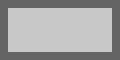

In [83]:
def rysuj_ramke_szare(w, h, grub, kolor_ramki, kolor): #kolor od 0 do 255
    t = (h, w)
    tab = np.ones(t, dtype=np.uint8)
    tab[:] = kolor_ramki  # wypełnienie tablicy szarym kolorem o wartości kolor_ramki
    tab[grub:h-grub, grub:w-grub] = kolor  # wypełnienie podtablicy kolorem o wartości kolor
    return Image.fromarray(tab)


im_ramka = rysuj_ramke_szare(120, 60, 8, 100, 200)
im_ramka 

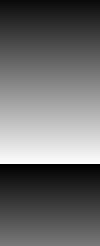

In [84]:
def rysuj_pasy_poziome_szare(w, h, grub, zmiana_koloru):  
    t = (h, w)
    tab = np.ones(t, dtype=np.uint8)
    ile = int(h / grub)
    for k in range(ile):
        for g in range(grub):
            i = k * grub + g
            for j in range(w):
                tab[i, j] = (3*k + zmiana_koloru) % 256
    return Image.fromarray(tab)


im_paski = rysuj_pasy_poziome_szare(100, 246, 2, 10)
im_paski


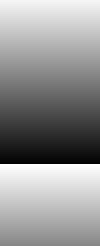

In [85]:
def negatyw_szare(obraz):  
    tab = np.asarray(obraz) 
    h, w = tab.shape
    tab_neg = tab.copy()
    for i in range(h):
        for j in range(w):
            tab_neg[i, j] = 255 - tab[i, j]
    return Image.fromarray(tab_neg)


obraz_neg = negatyw_szare(im_paski)
obraz_neg

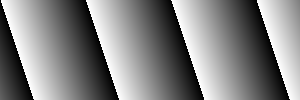

In [86]:
def rysuj_po_skosie_szare(h,w, a, b):  # formuła zmiany wartości elemntów tablicy a*i + b*j
    t = (h, w) # rysuje kwadratowy obraz
    tab = np.zeros(t, dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            tab[i, j] = (a*i + b*j) % 256 
    return Image.fromarray(tab)


im_skos = rysuj_po_skosie_szare(100, 300, 1, -3)
im_skos

obrazy w trybie RGB

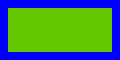

In [87]:
def rysuj_ramke_kolor(w, h, grub, kolor_ramki, kolor_tla):  # kolor_ramki, kolor podajemy w postaci [r, g, b]
    t = (h, w, 3)  # rozmiar tablicy
    tab = np.ones(t, dtype=np.uint8)  # deklaracja tablicy
    tab[:] = kolor_ramki  # wypełnienie tablicy kolorem kolor_ramki
    tab[grub:h - grub, grub:w - grub, 0] = kolor_tla[0]  #  wartości kanału R 
    tab[grub:h - grub, grub:w - grub, 1] = kolor_tla[1]  #  wartości kanału G 
    tab[grub:h - grub, grub:w - grub, 2] = kolor_tla[2]  #  wartości kanału B 
    # tab[grub:h - grub, grub:w - grub] = kolor_tla # wersja równoważna
    return Image.fromarray(tab)


im_ramka_kolor = rysuj_ramke_kolor(120, 60, 8, [0, 0, 255], [100, 200, 0])
im_ramka_kolor


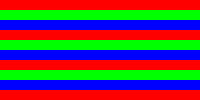

In [88]:
def rysuj_pasy_poziome_3kolory(w, h, grub):  # funkcja rysuje pasy poziome na przemian czerwony, zielony, niebieski
    t = (h, w, 3)
    tab = np.ones(t, dtype=np.uint8)
    ile = int(h / grub)
    for k in range(ile):
        for g in range(grub):
            i = k * grub + g
            for j in range(w):
                if k % 3 == 0:
                    tab[i, j] = [255, 0, 0]
                elif k % 3 == 1:
                    tab[i, j] = [0, 255, 0]
                else:
                    tab[i, j] = [0, 0, 255]
    return Image.fromarray(tab)


obraz1 = rysuj_pasy_poziome_3kolory(200, 100, 10)
obraz1


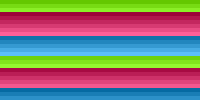

In [89]:
def rysuj_pasy_poziome_kolor(w, h, grub, kolor,
                             zmiana_koloru):  # funkcja rysuje pasy poziome, przy czym kazda składowa koloru zwieksza się o "zmiana_koloru"
    t = (h, w, 3)
    tab = np.ones(t, dtype=np.uint8)
    tab[:] = kolor
    ile = int(h / grub)
    for k in range(ile):
        r = (kolor[0] + k * zmiana_koloru) % 256
        g = (kolor[1] + k * zmiana_koloru) % 256
        b = (kolor[2] + k * zmiana_koloru) % 256
        for m in range(grub):
            i = k * grub + m
            for j in range(w):
                tab[i, j] = [r, g, b]
    return Image.fromarray(tab)


obraz2 = rysuj_pasy_poziome_kolor(200, 100, 4, [100, 200, 0], 19)
obraz2


Dlaczego jest efekt "przeskakiwania" koloru?

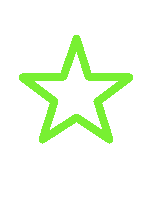

In [90]:
def koloruj_obraz(obraz, kolor):
    t_obraz = np.asarray(obraz)
    h, w = t_obraz.shape
    t =(h, w, 3)
    tab = np.ones(t, dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            if t_obraz[i, j] == False:
                tab[i, j] = kolor
            else:
                tab[i, j] = [255, 255, 255]
    return Image.fromarray(tab)

gwiazdka = Image.open("gwiazdka.bmp")
koloruj_obraz(gwiazdka, [120, 240, 50])


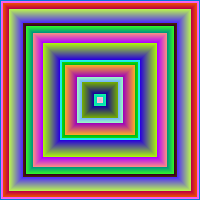

In [91]:
def rysuj_ramki_kolorowe(w, kolor, zmiana_koloru_r, zmiana_koloru_g, zmiana_koloru_b):
    t = (w, w, 3)
    tab = np.zeros(t, dtype=np.uint8)
    kolor_r = kolor[0]
    kolor_g = kolor[1]
    kolor_b = kolor[2]
    z = w
    for k in range(int(w / 2)):
        for i in range(k, z - k):
            for j in range(k, z - k):
                tab[i, j] = [kolor_r, kolor_g, kolor_b]
        kolor_r = (kolor_r - zmiana_koloru_r) % 256
        kolor_g = (kolor_g - zmiana_koloru_g) % 256
        kolor_b = (kolor_b - zmiana_koloru_b) % 256
    return Image.fromarray(tab)


obraz3 = rysuj_ramki_kolorowe(200, [0,120,220], 8, 15, -13)
obraz3

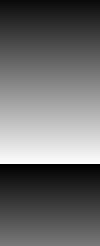

In [92]:
def rysuj_pasy_poziome_szare(w, h, grub, zmiana_koloru):  
    t = (h, w)
    tab = np.ones(t, dtype=np.int_)
    ile = int(h / grub)
    for k in range(ile):
        for g in range(grub):
            i = k * grub + g
            for j in range(w):
                tab[i, j] = (3*k + zmiana_koloru) 
    return Image.fromarray(tab.astype(np.uint8))


im_paski = rysuj_pasy_poziome_szare(100, 246, 2, 10)
im_paski

tryb obrazu:  L


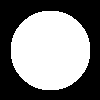

In [93]:
def rysuj_kolo(w, h, r, m, n, kolor): # koło o promieniu r i środku m, n, kolor = 0 lub 255
    t = (h, w) # rysuje kwadratowy obraz
    tab = np.zeros(t, dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            if (i-n)**2+(j-m)**2 < r**2: # wzór na koło o środku (m_s, n_s) i promieniu r
                tab[i, j] = kolor 
            else: 
                tab[i, j] = 255 - kolor 
    return tab

kolo_im = Image.fromarray(rysuj_kolo(100,100,40,50,50, 255))
print("tryb obrazu: ", kolo_im.mode)
kolo_im

kanały obrazu RGB

In [94]:
im_ramki = rysuj_ramki_kolorowe(100,[20, 30, 0], 13, 4, 10)
tab_ramki = np.asarray(im_ramki)
t_r = tab_ramki[:, :, 0]
print("typ danych tablicy kanału r: ", t_r.dtype)
print("rozmiar elemntu tablicy kanału r: ",t_r.itemsize)
print("rozmiar tablicy kanału r: ",t_r.shape)
print("wymiar tablicy kanału r: ",t_r.ndim)
im_r = Image.fromarray(t_r) # obraz w odcieniach szarości kanału r
print("tryb kanału r: ", im_r.mode)

t_g= tab_ramki[:, :, 1]
im_g = Image.fromarray(t_g) # obraz w odcieniach szarości kanału g

t_b = tab_ramki[:, :, 2]
im_b = Image.fromarray(t_b) # obraz w odcieniach szarości kanału b

typ danych tablicy kanału r:  uint8
rozmiar elemntu tablicy kanału r:  1
rozmiar tablicy kanału r:  (100, 100)
wymiar tablicy kanału r:  2
tryb kanału r:  L


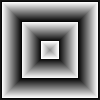

In [95]:
im_r

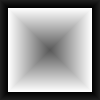

In [96]:
im_g

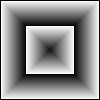

In [97]:
im_b

Tworzenie obrazu RGBA

rozmiar tablicy kanału a:  (100, 100)
rozmiar tablicy rgb:  (100, 100, 3)
rozmiar tablicy a_ext:  (100, 100, 1)
rozmiar tablicy combined:  (100, 100, 4)
tryb obrazu:  RGBA


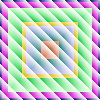

In [98]:

im_skos = rysuj_po_skosie_szare(100, 100, 20, -20) # tablica kanału alfa
tab_skos = np.asarray(im_skos)

print("rozmiar tablicy kanału a: ", tab_skos.shape)

print("rozmiar tablicy rgb: ", tab_ramki.shape)

# Rozszerzenie wymiaru tablicy a 
a_ext = np.expand_dims(tab_skos, axis=-1)
print("rozmiar tablicy a_ext: ", a_ext.shape)
# Połączenie wzdłuż ostatniego wymiaru
combined = np.concatenate((tab_ramki, a_ext), axis=-1) # tak samo działa linijka poniżej
#combined = np.stack((tab_ramki[..., 0], tab_ramki[..., 1], tab_ramki[..., 2], a_ext[..., 0]), axis=-1)
print("rozmiar tablicy combined: ", combined.shape)
rgba_im = Image.fromarray(combined)
print("tryb obrazu: ", rgba_im.mode)
rgba_im

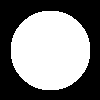

In [99]:
tab_kolo = rysuj_kolo(100,100,40,50,50,255) # tablica kanału alfa
im_kolo = Image.fromarray(tab_kolo)
im_kolo

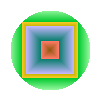

In [100]:
a_ext = np.expand_dims(tab_kolo, axis=-1)
combined = np.concatenate((tab_ramki, a_ext), axis=-1)

rgba_im1 = Image.fromarray(combined)
rgba_im1 # białe piksele kanału alfa pokazują obraz a czarne piksele powodują, że obraz jest przezroczysty

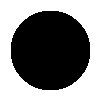

In [101]:
tab_kolo2 = rysuj_kolo(100,100,40,50,50,0) # tablica kanału alfa
im_kolo2 = Image.fromarray(tab_kolo2)
im_kolo2

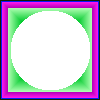

In [102]:
a_ext = np.expand_dims(tab_kolo2, axis=-1)
combined = np.concatenate((tab_ramki, a_ext), axis=-1)

rgba_im2 = Image.fromarray(combined)
rgba_im2 # białe piksele kanału alfa pokazują obraz a czarne piksele powodują, że obraz jest przezroczysty

Tworzenie obrazu w trybie CMYK na bazie tablicy obrazu RGBA

In [103]:
cmyk_im = Image.fromarray(combined, mode='CMYK') # ta sama tablica co obrazu rgba

cmyk_im.save('cmyk.jpg') # png nie obsługuje trybu 'CMYK'



Konwersja RGB na tryb CMYK

In [104]:

def rgb_to_cmyk(rgb_array):
    # Przekształć wartości RGB na zakres [0, 1]
    rgb = rgb_array.astype(float) / 255
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]

    # Oblicz kanał k (black)
    k = 1 - np.max(rgb, axis=2)

    # Uniknij dzielenia przez zero
    c = (1 - r - k) / (1 - k + 1e-8)
    m = (1 - g - k) / (1 - k + 1e-8)
    y = (1 - b - k) / (1 - k + 1e-8)

   
    # Przekształć na zakres [0, 255]
    cmyk = np.stack((c, m, y, k), axis=2) * 255
    return cmyk.astype(np.uint8)




# Konwersja do CMYK
t_cmyk = rgb_to_cmyk(tab_ramki)


image_cmyk = Image.fromarray(t_cmyk, mode="CMYK")
image_cmyk.save("obraz_cmyk.jpg")


In [105]:
im = Image.open('obraz_cmyk.jpg')
t_im = np.asarray(im)
print(t_im.shape)

(100, 100, 4)


In [106]:

t_c = t_im[:, :, 0]
print("typ danych tablicy kanału c: ", t_c.dtype)
print("rozmiar elemntu tablicy kanału c: ",t_c.itemsize)
print("rozmiar tablicy kanału c: ",t_c.shape)
im_c = Image.fromarray(t_c) # obraz w odcieniach szarości kanału c
print("tryb kanału c: ", im_c.mode)

t_m = t_im[:, :, 1]
im_m = Image.fromarray(t_m) # obraz w odcieniach szarości kanału m

t_y = t_im[:, :, 2]
im_y = Image.fromarray(t_y) # obraz w odcieniach szarości kanału y

t_k = t_im[:, :, 3]
im_k = Image.fromarray(t_k) # obraz w odcieniach szarości kanału k

typ danych tablicy kanału c:  uint8
rozmiar elemntu tablicy kanału c:  1
rozmiar tablicy kanału c:  (100, 100)
tryb kanału c:  L


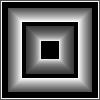

In [107]:
im_c

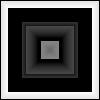

In [108]:
im_m

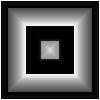

In [109]:
im_y

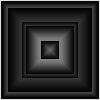

In [110]:
im_k